***Klasteryzacja na podstawie danych z EEG.***

@article{PhysioNet-multimodal-gait-dataset-1.0.0, <br>
  author = {Katmah, Rateb and AlShehhi, Aamna and Kosaji, Doua and Al-Rahmani, Nour and Abdullah, Muhammad and Hulleck, Abdul Aziz Vaqar and Khalaf, Kinda}, <br>
  title = {{A multimodal gait dataset of brain activity, muscle activity, kinematics and ground forces in young adults}}, <br>
  journal = {{PhysioNet}}, <br>
  year = {2026}, <br>
  month = apr,<br>
  note = {Version 1.0.0}, <br>
  doi = {10.13026/r0ea-7161}, <br>
  url = {https://doi.org/10.13026/r0ea-7161} <br>
}

@article{pollard_physionet_2026, title = {{PhysioNet} as a global platform for biomedical research}, <br>
volume = {1}, <br>
issn = {3005-0693}, <br> 
url = {https://doi.org/10.1038/s44360-026-00096-z}, <br>
doi = {10.1038/s44360-026-00096-z}, <br>
abstract = {Twenty-five years after its first public repository was established, the PhysioNet resource for biomedical and clinical data has enabled tens of thousands of research papers. Further efforts are ongoing to advance secure data sharing, community engagement and scalable research infrastructure.},<br> 
number = {8}, <br>
journal = {Nature Health}, author = {Pollard, Tom and Moody, Benjamin E. and Lehman, Li-wei H. and Gow, Brian J. and Fernandes, Chrystinne and Xie, Chen and Johnson, Alistair and Mark, Roger G. and Heldt, Thomas}, <br>
month = aug, <br>
year = {2026}, <br>
pages = {792--795},<br>
}

In [49]:
import pandas as pd
import numpy as np
import seaborn as sns   
import glob
import os 
import matplotlib.pyplot as plt 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.metrics import silhouette_score
from scipy.stats import f_oneway

Aby moc na danych pracowac (ponad 50 oddzielnych plikow .csv gdzie kazdy plik to jeden pacjent) nalezy je "skompresowac" do jednego DataFrame gdzie kazdy wiersz bedzie odpowiadal wariancji wynikow z kazdej elektrody (jest ich 24). <br>
Waznym jest policzenie wariancji a nie np sredniej ze wzgledu na specyfike danych neurologicznych. Jesli wiec dla kazdej elektrody mierzona jest roznica potencjalow (a ta jest zmienna dodatanie i ujemnie w czasie) to srednia pokazalaby wartosc bliska zeru, co nawet przy pomiarach wykazujacych problemy padaczkowe (duze amplitudy) nie zostaloby wychwycone przez model (srednia z liczb od -50 do 50 jest podobna do tej od -100 do 100 i oscyluje wokol 0).

In [50]:
#szukanie sciezek do plikow
files_path = r'C:/ML_Projects/ML_notebooks/EEG_Clustering/EEG_data/*_raw.csv'
files_list = glob.glob(files_path)
print(f"Znaleziono {len(files_list)} plikow.")

composed_data = []

for file in files_list:
    file_name = os.path.basename(file)
    try:
        patient = file_name.split('_')[0]
        condition = file_name.split('_')[1]
    except IndexError:
        continue

    df = pd.read_csv(filepath_or_buffer=file, skiprows=15)

    if 'Time' in df.columns:
        df = df.drop(columns=['Time'])

    single_row = {
        'Patient': patient,
        'Condition': condition
    }
    #zmiana formatu tabeli z dwuwymiarowej do plaskiej
    for electrod in df.columns:
        
        #zamiana wartosci nieliczbowych na Nan
        signal = pd.to_numeric(df[electrod], errors='coerce')
        
        #ignorowanie Nan
        if signal.isna().all():
            continue

        single_row[f'{electrod}_RMS'] = np.sqrt((signal**2).mean())
        single_row[f'{electrod}_Std'] = signal.std()

    composed_data.append(single_row)

#finalny kszalt tabeli
df_final = pd.DataFrame(composed_data)
df_final    

Znaleziono 177 plikow.


,Patient,Condition,P3_RMS,P3_Std,C3_RMS,C3_Std,F3_RMS,F3_Std,Fz_RMS,Fz_Std,...,C2_RMS,C2_Std,???_RMS,???_Std,???.1_RMS,???.1_Std,???.2_RMS,???.2_Std,A2.1_RMS,A2.1_Std
0,S10,0.5,1348.644441,90.345783,483.717911,86.473999,458.911144,72.031502,387.027849,66.676038,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,S10,0.75,899.354358,98.903809,291.799761,90.450915,276.581236,45.761969,255.058521,61.036144,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,S10,1,566.601523,106.971049,617.449976,146.202938,73.482296,57.603441,125.360762,81.749748,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,S11,0.5,131.844047,13.509187,130.394625,63.555553,183.061385,29.697160,140.320277,27.003068,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,S11,0.75,38.932269,23.821100,363.156406,41.348940,102.962140,38.627279,95.442892,43.229516,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,S8,0.75,99.612436,44.211854,51.854227,48.814082,120.885496,50.766085,358.577386,53.232795,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
173,S8,1,66.973116,65.062328,58.271142,56.521865,203.181840,118.813918,400.541495,98.689690,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
174,S9,0.5,769.275027,98.941693,1470.386679,324.122920,1597.299595,267.881798,877.769450,286.124809,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
175,S9,0.75,328.272281,191.313637,823.740706,376.597684,537.853676,326.069537,460.652309,361.066138,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DataFrame ma juz finalny strukture, pacjent, condition i parametry. <br>
Podczas preprocessingu w tabeli pojawiaja sie smieciowe kolumny ktore sa skutkiem ubocznym wczesniejszych dzialan, nalezy ja usunac aby nie przeszkadzaly w trenowaniu modelu.

In [51]:
to_drop = []

for col in df_final.columns:
    if df_final[col].isna().sum() > len(df_final[col])/2:
        to_drop.append(col)

print(to_drop)

['F6_RMS', 'F6_Std', '?_RMS', '?_Std', '?.1_RMS', '?.1_Std', '?.2_RMS', '?.2_Std', 'C2_RMS', 'C2_Std', '???_RMS', '???_Std', '???.1_RMS', '???.1_Std', '???.2_RMS', '???.2_Std', 'A2.1_RMS', 'A2.1_Std']


In [52]:
df_final = df_final.drop(columns=to_drop, errors='ignore')
df_final

,Patient,Condition,P3_RMS,P3_Std,C3_RMS,C3_Std,F3_RMS,F3_Std,Fz_RMS,Fz_Std,...,Trigger_RMS,Trigger_Std,Time_Offset_RMS,Time_Offset_Std,ADC_Status_RMS,ADC_Status_Std,ADC_Sequence_RMS,ADC_Sequence_Std,Event_RMS,Event_Std
0,S10,0.5,1348.644441,90.345783,483.717911,86.473999,458.911144,72.031502,387.027849,66.676038,...,36.0,0.0,62212.586911,31108.420653,0.0,0.0,147.286409,73.830665,0.0,0.0
1,S10,0.75,899.354358,98.903809,291.799761,90.450915,276.581236,45.761969,255.058521,61.036144,...,36.0,0.0,62211.900248,31108.110561,0.0,0.0,147.326399,73.822011,0.0,0.0
2,S10,1,566.601523,106.971049,617.449976,146.202938,73.482296,57.603441,125.360762,81.749748,...,36.0,0.0,62211.816219,31108.298838,0.0,0.0,147.385859,73.832968,0.0,0.0
3,S11,0.5,131.844047,13.509187,130.394625,63.555553,183.061385,29.697160,140.320277,27.003068,...,36.0,0.0,62212.666926,31108.498517,0.0,0.0,147.284851,73.831403,0.0,0.0
4,S11,0.75,38.932269,23.821100,363.156406,41.348940,102.962140,38.627279,95.442892,43.229516,...,36.0,0.0,62211.978926,31108.069255,0.0,0.0,147.294423,73.827429,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,S8,0.75,99.612436,44.211854,51.854227,48.814082,120.885496,50.766085,358.577386,53.232795,...,36.0,0.0,62212.666830,31108.498422,0.0,0.0,147.524514,73.913515,0.0,0.0
173,S8,1,66.973116,65.062328,58.271142,56.521865,203.181840,118.813918,400.541495,98.689690,...,36.0,0.0,62212.666926,31108.498517,0.0,0.0,147.219708,73.928126,0.0,0.0
174,S9,0.5,769.275027,98.941693,1470.386679,324.122920,1597.299595,267.881798,877.769450,286.124809,...,36.0,0.0,62212.666926,31108.498517,0.0,0.0,147.214398,73.952066,0.0,0.0
175,S9,0.75,328.272281,191.313637,823.740706,376.597684,537.853676,326.069537,460.652309,361.066138,...,36.0,0.0,62211.803835,31108.405223,0.0,0.0,147.566115,73.946536,0.0,0.0


Dane zostaly skutecznie wyczyszcone, pora sie im dokladniej przyjrzec od strony matematycznej i zaczynac budowac pipeline.

In [53]:
df_final.describe()

,P3_RMS,P3_Std,C3_RMS,C3_Std,F3_RMS,F3_Std,Fz_RMS,Fz_Std,F4_RMS,F4_Std,...,Trigger_RMS,Trigger_Std,Time_Offset_RMS,Time_Offset_Std,ADC_Status_RMS,ADC_Status_Std,ADC_Sequence_RMS,ADC_Sequence_Std,Event_RMS,Event_Std
count,177.000000,177.000000,177.000000,177.000000,177.000000,177.000000,177.000000,177.000000,176.000000,176.000000,...,177.000000,177.000000,177.000000,177.000000,1.770000e+02,1.770000e+02,177.000000,177.000000,177.0,177.0
mean,427.560089,138.502735,494.528088,197.505380,569.408253,229.183617,552.912802,164.932213,632.502662,279.183726,...,33.816846,0.156432,62386.358611,31203.821106,6.329339e+04,5.676157e+04,147.380286,73.892696,0.0,0.0
std,492.394000,204.428615,536.744512,254.187425,658.971470,388.592605,561.822570,206.449117,656.002981,412.987628,...,8.401700,1.189740,2313.971174,1269.581599,7.715190e+05,7.344866e+05,0.125835,0.069798,0.0,0.0
min,23.242440,10.758734,37.426411,21.548944,51.557137,26.096981,45.701925,23.131324,48.752681,25.921246,...,1.170917,0.000000,62210.063511,31107.307383,0.000000e+00,0.000000e+00,147.208271,73.657325,0.0,0.0
25%,109.910376,36.642083,138.821867,57.136885,199.982746,59.859628,168.904324,55.138626,191.728033,71.297681,...,36.000000,0.000000,62212.306951,31108.356272,0.000000e+00,0.000000e+00,147.271513,73.832968,0.0,0.0
50%,223.376128,71.938209,299.630826,103.738092,386.350471,105.546041,412.239201,90.992336,382.479791,126.990290,...,36.000000,0.000000,62212.666926,31108.498517,0.000000e+00,0.000000e+00,147.361089,73.872613,0.0,0.0
75%,607.431039,143.021945,656.690268,208.078266,676.347047,249.945600,686.171382,180.378276,859.442948,268.298845,...,36.000000,0.000000,62212.666926,31108.498517,7.400218e+03,9.053035e+02,147.482553,73.946536,0.0,0.0
max,3602.215709,1380.334828,3192.897071,1499.470709,4064.537618,3253.267084,3572.651746,1688.810901,4048.948969,2428.464975,...,36.000000,15.485709,92997.813503,47999.077909,1.026887e+07,9.773121e+06,147.786867,74.029916,0.0,0.0


Jako ze sa to dane z EEG to poprzez znajomosc specyfiki tego badania wiadomo ze nie wystapia tutaj kolumny binarne, a co za tym idzie najlepszym graficznym przedstawieniem danych bedzie boxplot.

Problem jednak pojawia sie ze wzgledu na ilosc kolumn (62!). <br>
Do skutecznego zajrzenia w dane w takiej sytuacji pomaga mapa korelacji.

<Axes: title={'center': 'Macierz korelacji'}>

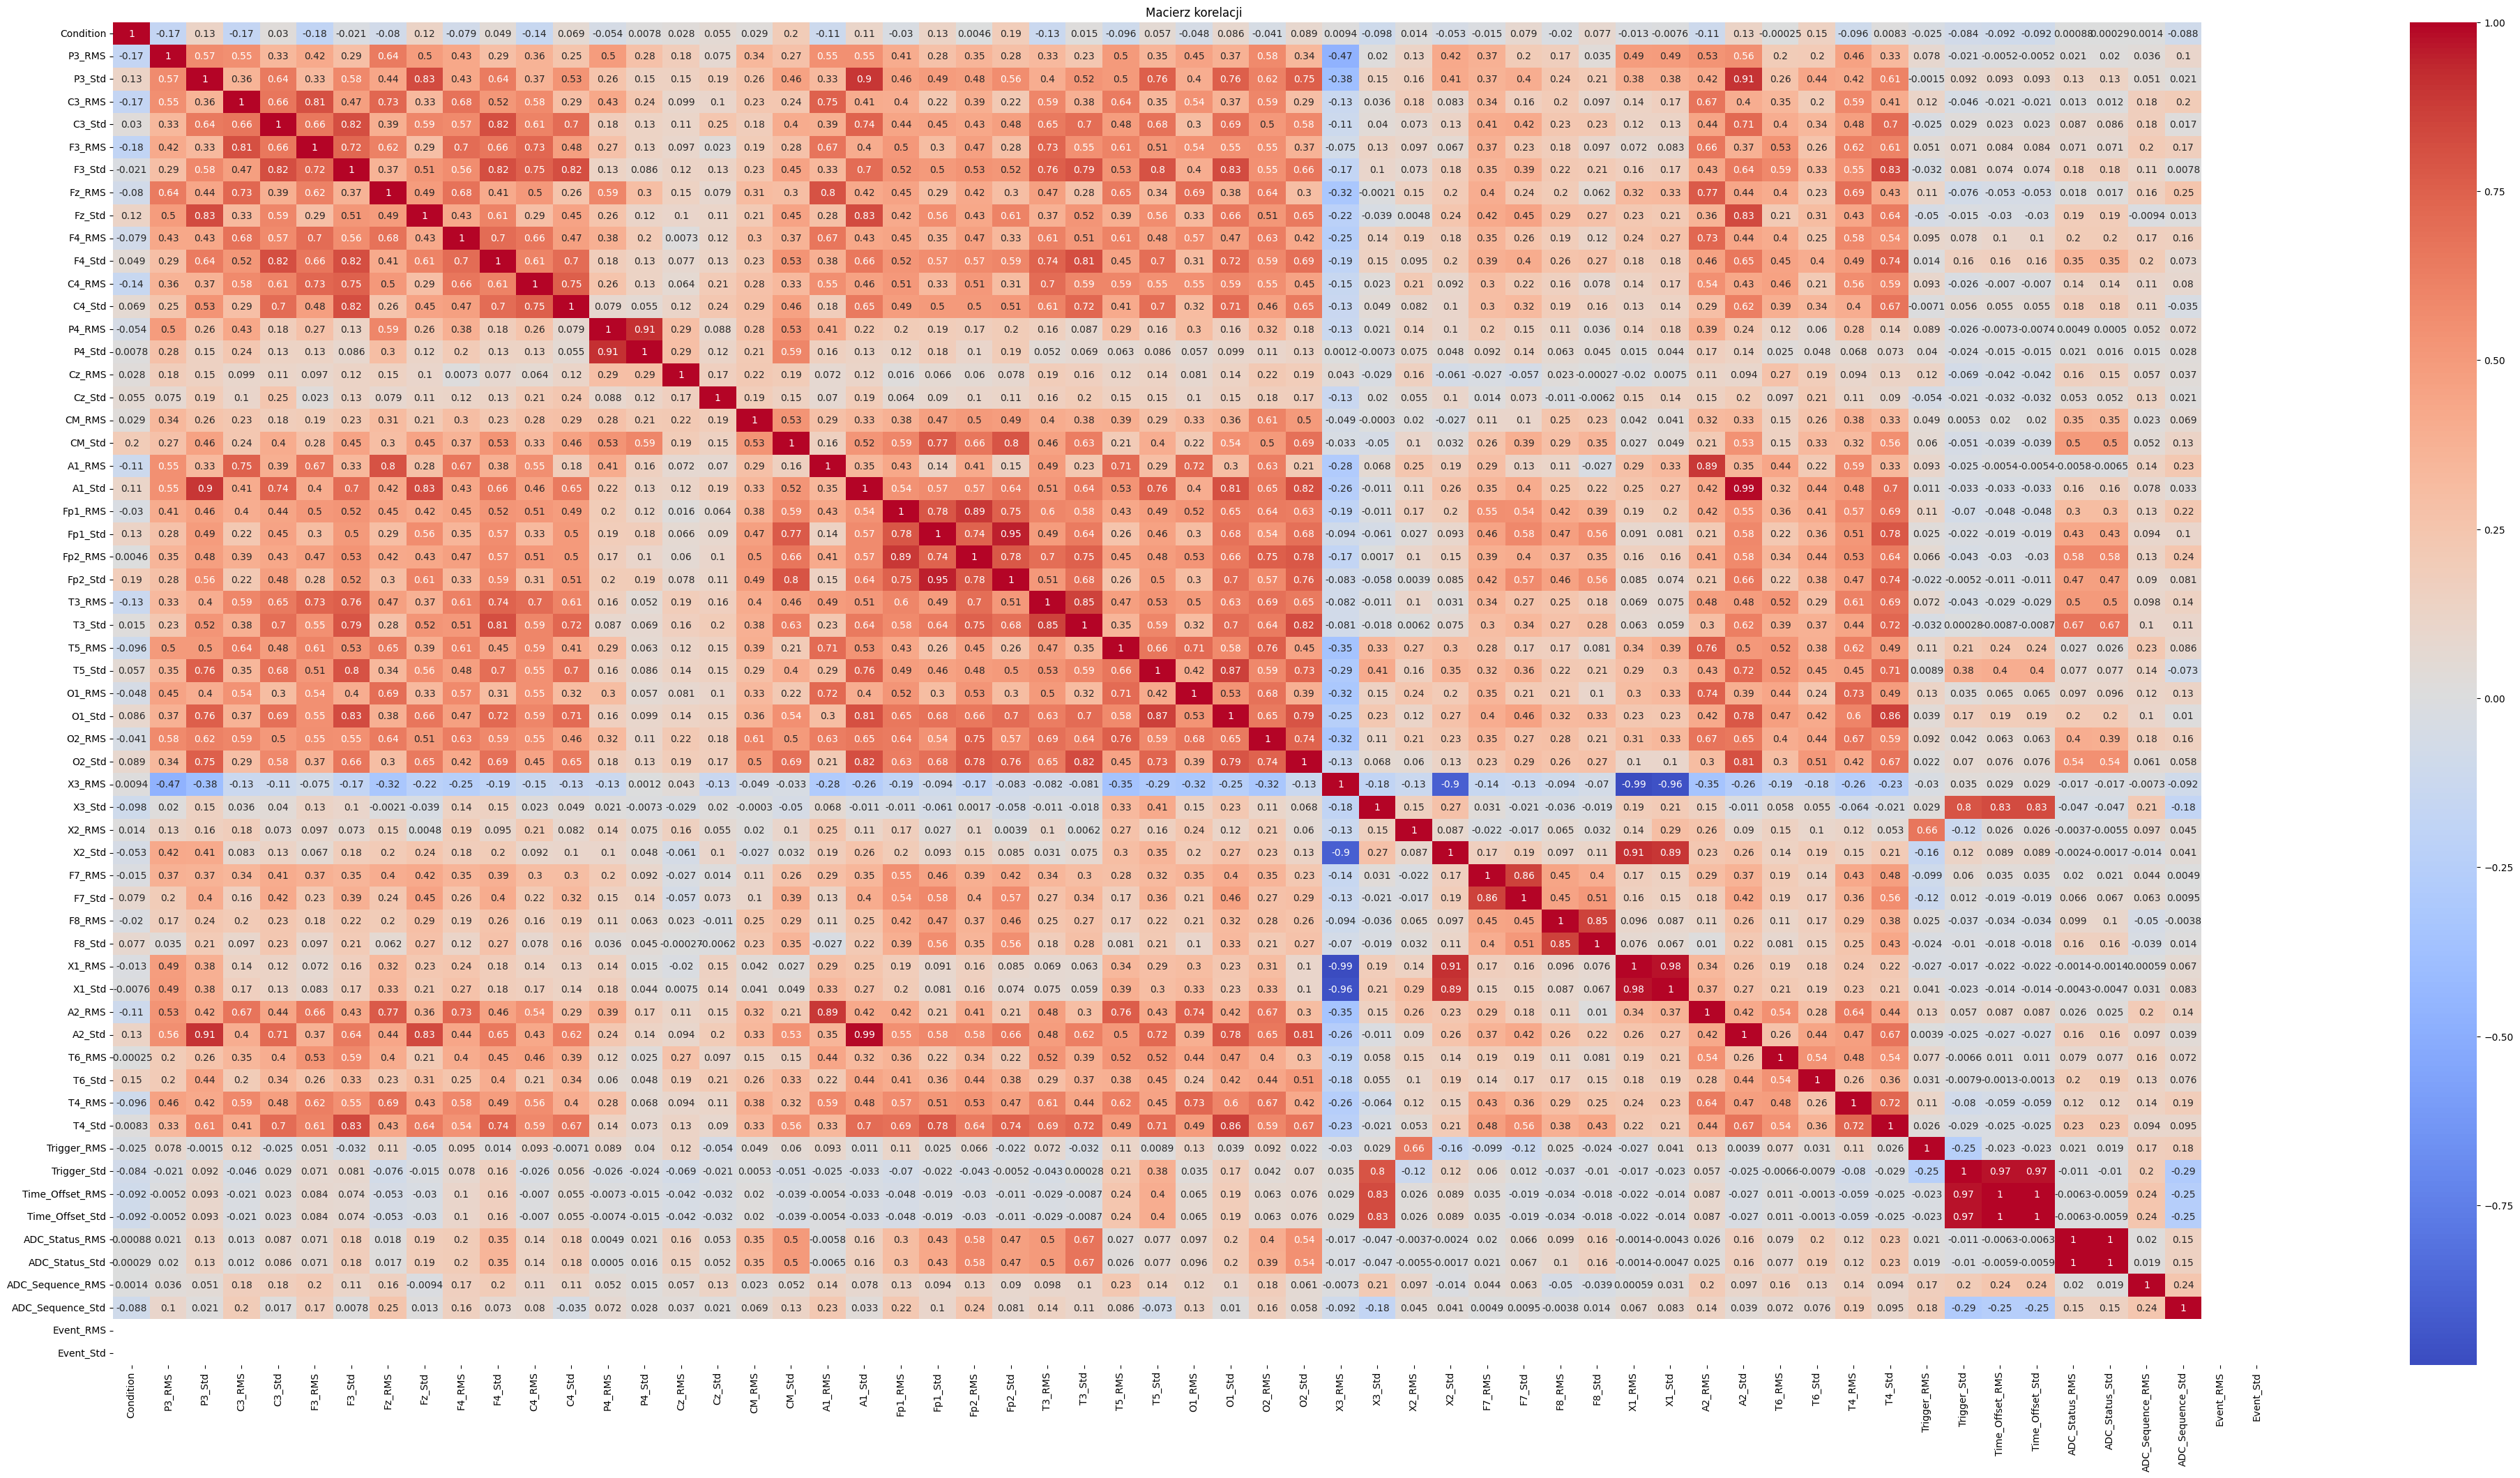

In [54]:
plt.figure(figsize=(50, 25))
plt.title('Macierz korelacji')
corr = df_final.iloc[:, 1:].corr()
sns.heatmap(data=corr, annot=True, cmap='coolwarm')


Problemem jest ogrom danych, nawet macierz korelacji nie spelnia swoich zadan poniewaz jest nieczytelna. <br>
W tym miejscu warto dane przeskalowac a pozniej uzyc algorytmu PCA do splaszczenia ich do kilku kolumn ktore beda zawierac najwazniejsze informacje.

In [55]:
X = df_final.drop(columns=['Patient', 'Condition'], errors='ignore')

prep_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('scaler', StandardScaler()), 
                    ('pca', PCA(n_components=0.95)) #n_components = 0.95 aby PCA zachowal 95% pierwotnych informacji
])

W przypadku badania EEG 5% danych ktore odrzucamy to bledy wynikajace ze specyfiki badania, pot na skorze, odklejona elektroda itp. <br>
Dlatego zostawia sie ten ulamek "backapu".

In [56]:
X_pca = prep_pipe.fit_transform(X)

In [57]:
print(f'Ksztalt przed pipelinem: {X.shape}')
print(f'Ksztalt po pipelinie: {X_pca.shape}')

Ksztalt przed pipelinem: (177, 58)
Ksztalt po pipelinie: (177, 22)


W dalszym ciagu dane maja 22 wymiary co jest nie do ogarniecia dla ludzkiego mozgu. <br>
W takiej sytuacji wybiera sie dwie pierwsze kolumny (ktore przez algorytm PCA sa sortowane od najwazniejszej do najmniej waznej).<br>
Dlatego wybieramy dwa pierwsze komponenty i robimy z nich wykres.

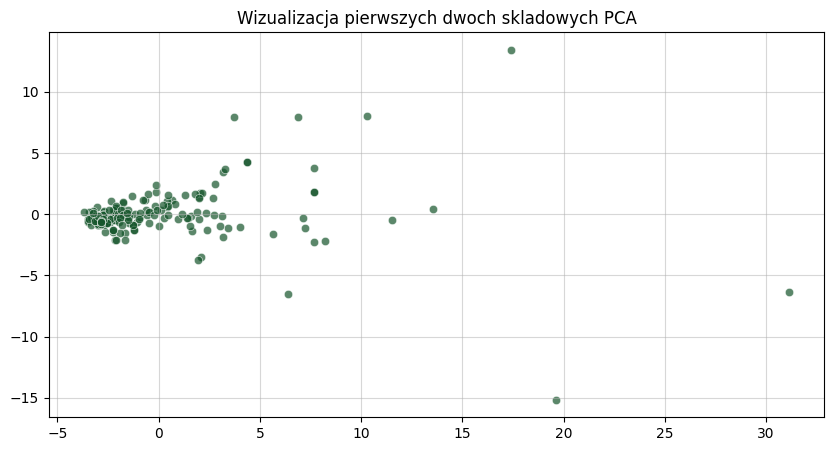

In [58]:
plt.figure(figsize=(10, 5))
plt.title('Wizualizacja pierwszych dwoch skladowych PCA')
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:,1], alpha=0.7, color="#15552b")
plt.grid(alpha=0.5)
plt.show()

Jak widac na wykresie na ten moment nie klaruja sie zadne widoczne dla ludzkiego oka klastry, nalezy oddac to modelom uczenia maszynowego zeby to one okreslily co sie moze tutaj klarowac.

Na pomoc przychodzia Elbow Method (Metoda Łokcia) ktora pomaga graficznie wyliczyc ilosc klastrow dla ktorej podzial ma najwiekszy sens (czyli sprawdzenie dla jakiego "K" nastepuje zagiecie w lokciu zaleznie od inercji).

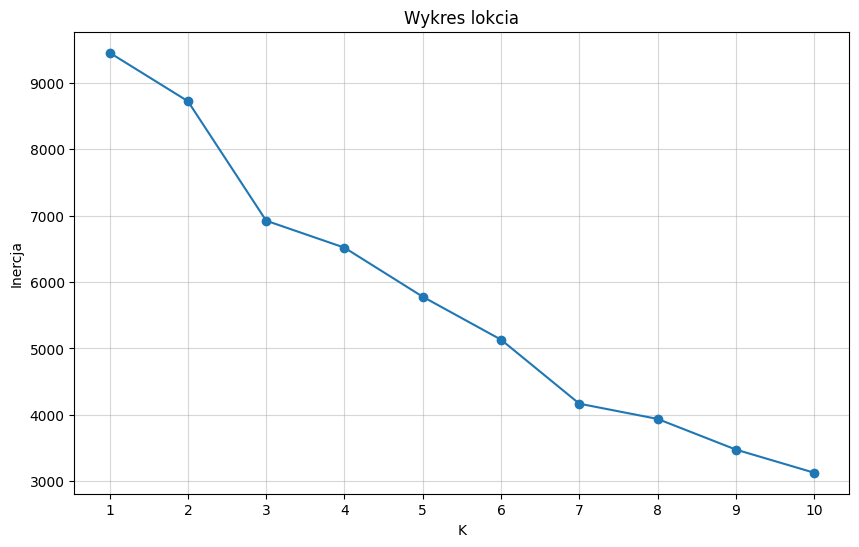

In [59]:
inertia = []
claster_range = range(1, 11)

for claster in claster_range:
    kmeans = KMeans(n_clusters=claster, random_state=42)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10,6))
plt.title('Wykres lokcia')
plt.xlabel('K')
plt.ylabel('Inercja')
plt.plot(claster_range, inertia, marker='o')
plt.xticks(claster_range)
plt.grid(alpha=0.5)
plt.show()

In [77]:
k=3

kmeans_params = {
    'k': k 
}

Pora na szukanie Eps jako glownego parametru DBSCAN.

In [78]:
#sztywne ustalenie min_samples
min_samples = X_pca.shape[1] * 2

#liczenie odleglosci miedzy danymi
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_pca)
distances, indices = neighbors_fit.kneighbors(X_pca)

#dystanse do najdalszego sasiada
k_distances = np.sort(distances[:,-1])

#uzycie biblioteki kneed do szukania zagiecia
kneedle = KneeLocator(
    range(len(k_distances)), 
    k_distances, 
    S=1.0, 
    curve="convex", 
    direction="increasing"
)

optimal_eps = k_distances[kneedle.knee]

print(f'Wartosci do DBSCAN')
print(f'min_samples: {min_samples}')
print(f'eps {optimal_eps:.2f}')

Wartosci do DBSCAN
min_samples: 44
eps 10.14


In [79]:
DBSCAN_params = {
    'min_samples': min_samples,
    'eps': optimal_eps
}

Po dobraniu odpowiednich parametrow pora na zbudowanie finalnego pipelinu.

In [80]:
pipelines = {
    'kmeans': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95)),
        ('model', KMeans(n_clusters=kmeans_params['k'], random_state=42))
        ]),
    'dbscan': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95)), 
        ('model', DBSCAN(min_samples=DBSCAN_params['min_samples'], eps=DBSCAN_params['eps']))
        ])
}

In [81]:
for name, pipeline in pipelines.items():
    labels = pipeline.fit_predict(X)

    df_final[f'Cluster_{name}'] = labels

df_final[['Patient', 'Condition', 'Cluster_kmeans', 'Cluster_dbscan']].head(10)

,Patient,Condition,Cluster_kmeans,Cluster_dbscan
0,S10,0.5,0,0
1,S10,0.75,0,0
2,S10,1,0,0
3,S11,0.5,0,0
4,S11,0.75,0,0
5,S11,1,0,0
6,S12,0.5,0,0
7,S12,0.75,0,0
8,S12,1,0,0
9,S13,0.5,0,0


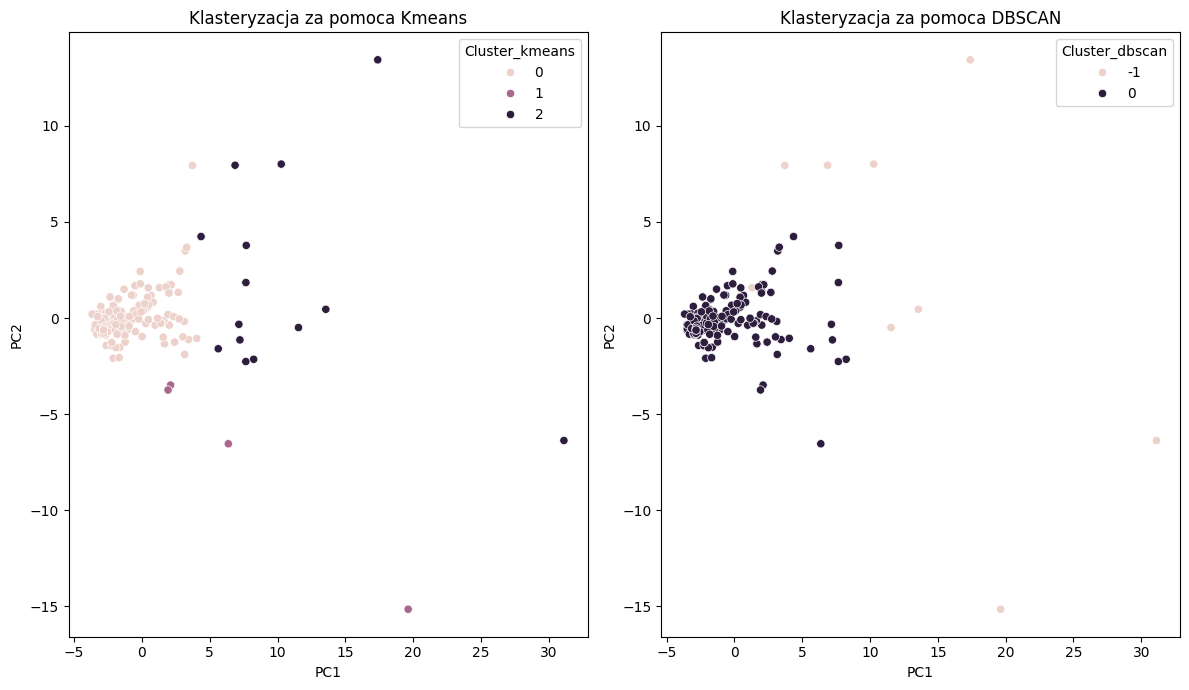

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_final['Cluster_kmeans'],
    ax=axes[0]
)
axes[0].set_title('Klasteryzacja za pomoca Kmeans')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_final['Cluster_dbscan'],
    ax=axes[1]
)
axes[1].set_title('Klasteryzacja za pomoca DBSCAN')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

In [83]:
#silhouette score
results = {}

for cluster in df_final[['Cluster_kmeans', 'Cluster_dbscan']]:
    score = silhouette_score(X=X_pca, labels=df_final[cluster])
    results[cluster] = score

print(results)

{'Cluster_kmeans': 0.5373455244357698, 'Cluster_dbscan': 0.6629993191608371}


DBSCAN poradzil sobie z szumem o wiele lepiej bo byl w stanie wogole go rozpoznac i sklasyfikowac, w przypadku KMeans juz tak dobrze nie bylo ze wzgledu na samo dzialanie modelu - musi on przypisac kazdy record do jakiegos klastra. <br>
Stad tez bardzo niski wynik silhouette score dla kmeans. <br>
Majac te informacje z DBSCAN mozemy usunac szum i zobaczyc jak na zmodyfikowanych danych bez zadnych artefaktow poradzi sobie ten drugi model.

In [84]:
df_clean = df_final[df_final['Cluster_dbscan'] != -1].copy()

X_clean = df_clean.drop(columns=['Patient', 'Condition', 'Cluster_kmeans', 'Cluster_dbscan'], errors='ignore')

In [85]:
#pipeline do przygotowania nowych danych
X_pca_clean = prep_pipe.fit_transform(X_clean)

#powtorka z pipelinu teraz na dancyh PCA stworzonych na podstawie odrzuconych klastrow -1 z DBSCAN
for name, pipeline in pipelines.items():
    labels_clean = pipeline.fit_predict(X_clean)

    df_clean[f'Cluster_{name}_clean'] = labels_clean

df_clean[['Patient', 'Condition', 'Cluster_kmeans_clean', 'Cluster_dbscan_clean']].head(10)

,Patient,Condition,Cluster_kmeans_clean,Cluster_dbscan_clean
0,S10,0.5,0,0
1,S10,0.75,0,0
2,S10,1,0,0
3,S11,0.5,0,0
4,S11,0.75,0,0
5,S11,1,0,0
6,S12,0.5,0,0
7,S12,0.75,0,0
8,S12,1,0,0
9,S13,0.5,0,0


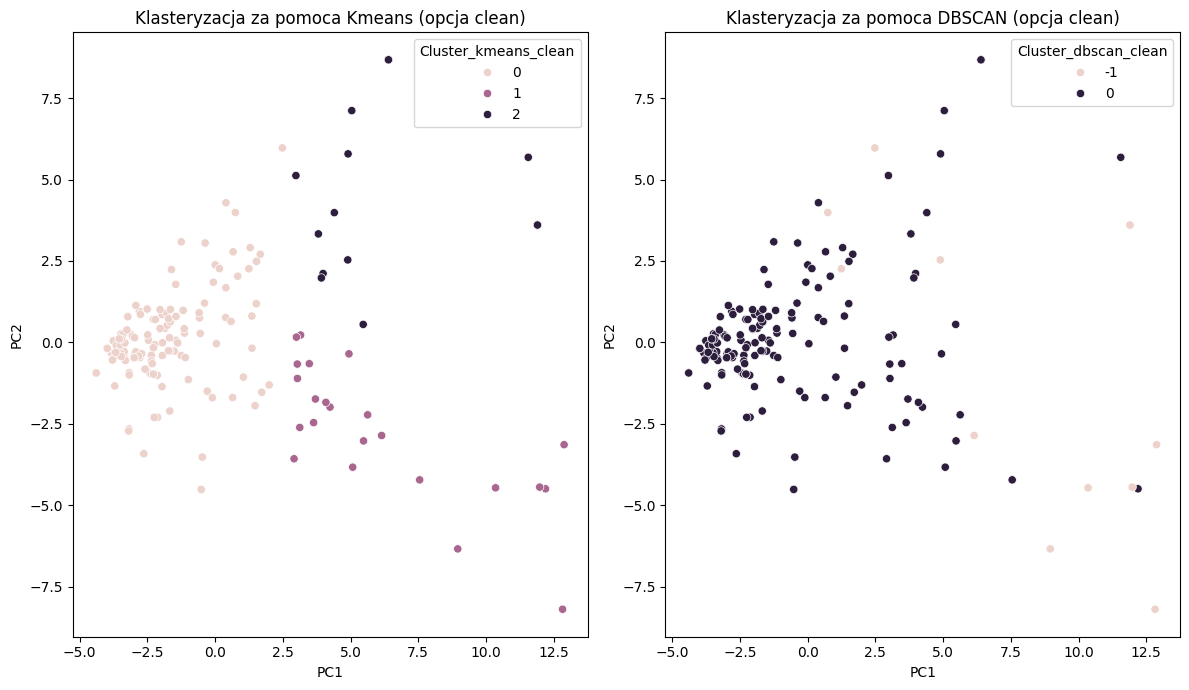

In [86]:
#oraz wizualizacja nowych klastrow
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.scatterplot(
    x=X_pca_clean[:, 0],
    y=X_pca_clean[:, 1],
    hue=df_clean['Cluster_kmeans_clean'],
    ax=axes[0]
)
axes[0].set_title('Klasteryzacja za pomoca Kmeans (opcja clean)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(
    x=X_pca_clean[:, 0],
    y=X_pca_clean[:, 1],
    hue=df_clean['Cluster_dbscan_clean'],
    ax=axes[1]
)
axes[1].set_title('Klasteryzacja za pomoca DBSCAN (opcja clean)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

In [87]:
#silhouette score
results = {}

for cluster in df_clean[['Cluster_kmeans_clean', 'Cluster_dbscan_clean']]:
    score = silhouette_score(X=X_pca_clean, labels=df_clean[cluster])
    results[cluster] = score

print(results)

{'Cluster_kmeans_clean': 0.35243988180976654, 'Cluster_dbscan_clean': 0.46949122208736055}


Jak widac wyni silhouette score dla kmeans po oczysczeniu danych jest znaczaco nizszy od tego pierwszego, w przypadku danych medycznych a tym bardziej z EEG jest to dosc normalne zjawisko. <br>
Silhouette score mierzy jak bardzo klastry sa zbite oraz oddalone od siebie. <br>
Skoro odrzucono szum i klastry staly sie w glownej mierze jednym duzym klebkiem danych to metryka wskazuje na dosc niski wynik. <br>
Nie jest to jednak sygnal mowiacy o calkowitym niepowodzeniu modelu. W takiej sytuacji nalezy porzucic matematyczne wyznaczniki i polegac na walidacji klinicznej.

Do tego przyda sie zbior danych subcjet-info.csv w ktorym zawarte sa informacje o pacjentach na ktorych przeprowadzono badanie. <br>
Nalezy przyjrzec sie do ktorego klastra zostal dany pacjent przypisany i wyciagniac wnosek czy model odnalazl w impulsach elektrycznych jakis sens medyczny.

In [88]:
info_path = r'C:/ML_Projects/ML_notebooks/EEG_Clustering/Subject_info_data/subject-info.csv'
df_info = pd.read_csv(filepath_or_buffer=info_path)

df_info = df_info[:59]
df_info = df_info.rename(columns={"Subject": "Patient"})
df_info.head()

,Patient,IMPAIRED/HEALTHY,GENDER,DOB,Age,HEIGHT(mm),BMI,WEIGHT(kg),FOOT LENGTH (mm),L-UPPER ARM,...,NECK,SHOULDER,C-CHEST,C-WAIST,C-HIP,C-THIGH,C-ANKLE,C-UPPER ARM,C-WRIST,Normal Speed (m/s)
0,S1,H,M,07/11/2002,22.0,1790.0,33.39,107.0,265.0,340.0,...,170.0,260.0,1190.0,990.0,1090.0,670.0,330.0,430.0,210.0,1.02
1,S2,H,M,10/09/2001,23.0,1660.0,18.51,51.0,250.0,330.0,...,130.0,220.0,800.0,760.0,830.0,370.0,260.0,260.0,180.0,0.92
2,S3,H,M,19/06/2002,22.0,1710.0,37.62,110.0,250.0,375.0,...,130.0,230.0,1220.0,1200.0,1280.0,670.0,300.0,430.0,230.0,0.99
3,S4,H,M,23/12/1987,37.0,1750.0,36.51,111.8,310.0,380.0,...,220.0,265.0,1180.0,1225.0,1280.0,680.0,310.0,395.0,205.0,1.02
4,S5,H,M,13/04/1997,27.0,1740.0,24.05,72.8,270.0,360.0,...,160.0,220.0,880.0,870.0,970.0,550.0,280.0,340.0,200.0,1.00


In [89]:
df_merged = pd.merge(left=df_clean, right=df_info, on='Patient', how='left')
df_merged[["Patient", "Condition", "IMPAIRED/HEALTHY", "BMI", "Normal Speed (m/s)", "Cluster_kmeans_clean", "Cluster_dbscan_clean"]]

,Patient,Condition,IMPAIRED/HEALTHY,BMI,Normal Speed (m/s),Cluster_kmeans_clean,Cluster_dbscan_clean
0,S10,0.5,H,27.02,1.00,0,0
1,S10,0.75,H,27.02,1.00,0,0
2,S10,1,H,27.02,1.00,0,0
3,S11,0.5,H,23.75,0.87,0,0
4,S11,0.75,H,23.75,0.87,0,0
...,...,...,...,...,...,...,...
163,S8,0.75,H,31.82,0.91,0,0
164,S8,1,H,31.82,0.91,0,0
165,S9,0.5,H,31.12,1.13,2,0
166,S9,0.75,H,31.12,1.13,1,0


In [90]:
crossed_table = pd.crosstab(df_merged["Cluster_kmeans_clean"], df_merged["Condition"])
crossed_table

Condition,0.5,0.75,1
Cluster_kmeans_clean,,,
0,41,46,44
1,5,7,11
2,10,3,1


In [91]:
df_merged.groupby('Cluster_kmeans_clean')[["Normal Speed (m/s)", "Age", "BMI"]].mean()

,Normal Speed (m/s),Age,BMI
Cluster_kmeans_clean,,,
0,1.040382,23.664122,25.200916
1,1.148696,26.043478,25.789565
2,1.080000,23.785714,23.681429


Wyniki klasteryzacji na pierwszy rzut oka wskazaly, ze model znalazl jakies zaleznosci miedzy pacjentami tylko i wylacznie z wynikow badania EEG. 
Problem jednak dzieje sie po przyjrzeniu sie liczebnosciom klastrow, widac jest wyraznie ze jeden z klastrow liczbowo dominuje o wiele bardziej od innych.
W takim wypadku albo modele odnalazly wyjatkowe roznice albo po prostu pogrupowaly pacjentow w jeden wielki klaster z lekkim szumem.
Spojrzmy jeszcze na test ANOVA

In [92]:
test_features = ['Age', 'BMI', 'Normal Speed (m/s)']

for feature in test_features:
    #pogrupowanie kazdej badanej cechy i kazdego klastra 
    group = [df_merged[df_merged['Cluster_kmeans_clean'] == k][feature] for k in sorted(df_merged['Cluster_kmeans_clean'].unique())]

    f_stat, p_value = f_oneway(*group)
    print('-' * 30)
    print(f"Cecha: {feature}")
    print(f"F-stat: {f_stat}")
    print(f"P-value: {p_value}")

    if p_value <= 0.05:
        print(f"Odrzucamy hipoteze zerowa, istotnosc cech jest prawdziwa.")
    else:
        print(f"Przyjeto hipoteze zerowa. Roznice nie sa istotne statystycznie.")


------------------------------
Cecha: Age
F-stat: 2.646644575391236
P-value: 0.07389734909288284
Przyjeto hipoteze zerowa. Roznice nie sa istotne statystycznie.
------------------------------
Cecha: BMI
F-stat: 0.9615051923253012
P-value: 0.3844485282189519
Przyjeto hipoteze zerowa. Roznice nie sa istotne statystycznie.
------------------------------
Cecha: Normal Speed (m/s)
F-stat: 5.49945927865726
P-value: 0.004873606478139944
Odrzucamy hipoteze zerowa, istotnosc cech jest prawdziwa.


Test ANOVA wyraznie pokazuje ze jedynie kolumna "Normal Speed" jest istotna statystycznie.

***Finalny werdykt***

Pomimo wykazania istotnosci statystycznej jednej z cech to cala klasteryzacja nie powiodla sie. <br>
Model nie znalazl zadnych sesnownych grup a jedynie jeden duzy zbior i pare danych odstajacych od niego. Moga byc to anomalie, wtedy trzebaby przeprowadzic analize w druga strone, jednak zalozeniem tego notebooka bylo klastrowanie datasetu i to sie nie powiodlo.
Czynnikiem powodujacym taki obrot sprawy moze byc specyfika danych - badanie ruchu mlodych ludzi.